# GeoQubit: hybrid quantum–classical inversion of a two-layer Wenner sounding

**Team GeoQubit** · Qiskit Fall Fest 2026 (UIQC Club) · [github.com/HE1MER25/GeoQubit](https://github.com/HE1MER25/GeoQubit)

| Member | Affiliation | Role |
|---|---|---|
| Praise Ayobami Ajulo-Omojesu | MSc Applied Geophysics, University of Ibadan | Project lead: geophysical theory, forward model, validation |
| John Wonderful Monday | BSc Physics, Obafemi Awolowo University | Quantum circuit architecture, variational optimisation |

**Question.** Can a small variational quantum circuit, tuned by a classical optimiser, recover the reflection coefficient $k$ and top-layer thickness $h$ of a two-layer earth from a Wenner resistivity sounding, and how does it compare with ordinary least squares?

**Answer in one line.** Yes it works (60/60 clean runs), but classical least squares needs roughly 20–50× fewer evaluations. We claim **no quantum advantage**; this notebook is a transparent, reproducible baseline.

**How to use this notebook.** *Runtime → Run all.* Everything is simulated (exact statevectors; finite shots are emulated by multinomial sampling). All random seeds are fixed. Set `QUICK = True` in the first code cell for a ~2-minute smoke test; `QUICK = False` reproduces the report-level statistics.

**Contents**
1. Forward model (method of images) and its validation
2. The variational circuit and the decoding map
3. Inversion: COBYLA versus least squares
4. The equivalence valley (misfit landscape)
5. Noise robustness
6. Finite-shot SPSA
7. Diagnostics added after judging feedback: gradient/initialisation study, circuit-size ablation, three-parameter inversion
8. Summary and limitations

In [1]:
import importlib.util, subprocess, sys
for _pkg in ("qiskit", "pylatexenc"):          # install on a fresh Colab runtime if missing
    if importlib.util.find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])
import time, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares
from scipy.integrate import quad
from scipy.special import j0
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector

QUICK = False            # True: fewer restarts / realisations for a fast smoke test
SEED  = 42
rng   = np.random.default_rng(SEED)

RHO1  = 100.0                                   # top-layer resistivity (ohm-m), assumed known
A_SP  = np.logspace(0, np.log10(50), 12)        # 12 Wenner spacings, 1 to 50 m
K_TRUE, H_TRUE = 0.6, 8.0                       # rho2 = 400 ohm-m, h = 8 m

plt.rcParams.update({"figure.dpi": 150, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
import qiskit; print("Qiskit", qiskit.__version__)

Qiskit 2.6.1


## 1. Forward model: Wenner apparent resistivity of a two-layer earth

For a Wenner array with equal electrode spacing $a$ over a layer of resistivity $\rho_1$ and thickness $h$ above a half-space $\rho_2$, define the **reflection coefficient**

$$k=\frac{\rho_2-\rho_1}{\rho_2+\rho_1},\qquad -1<k<1 .$$

The method of images treats the boundary and the free surface as two facing mirrors. The $n$-th image carries weight $k^{n}$ and sits at depth $2nh$. Summing the images gives the apparent resistivity

$$\rho_a \;=\; \rho_1\left[\,1 + 4\sum_{n=1}^{\infty}k^{\,n}\left(\frac{1}{\sqrt{1+(2nh/a)^{2}}}-\frac{1}{\sqrt{4+(2nh/a)^{2}}}\right)\right].$$

The factor 4 and the two square-root terms come from combining the four electrode–image distances of the Wenner geometry ($AM=NB=a$, $AN=MB=2a$). The geometric factor $K=2\pi a$ is already absorbed: the synthetic data are generated directly as $\rho_a$.

**Truncation.** Because $|k|<1$ the tail of the series is bounded by $2\rho_1|k|^{N+1}/(1-|k|)$. We choose $N$ so that this bound is below $10^{-8}$.

**Independent check (Hankel transform).** The same quantity can be computed without images:

$$\rho_a=\rho_1\left[1+4a\int_0^\infty K(\lambda)\,\big(J_0(\lambda a)-J_0(2\lambda a)\big)\,d\lambda\right],\qquad K(\lambda)=\frac{k\,e^{-2\lambda h}}{1-k\,e^{-2\lambda h}} .$$

In [2]:
def n_terms(k, tol=1e-8):
    # smallest N with 2*|k|^(N+1)/(1-|k|) < tol, clipped to [20, 5000]
    k = abs(k)
    if k < 1e-12: return 20
    return int(np.clip(np.ceil(np.log(tol*(1-k)/2)/np.log(k)), 20, 5000))

def rho_a(a, rho1, k, h, N=None):
    # Wenner apparent resistivity, two layers, image series
    a = np.atleast_1d(np.asarray(a, float))
    N = n_terms(k) if N is None else N
    n = np.arange(1, N+1)[:, None]
    t = 2*n*h/a[None, :]
    s = (k**n)*(1/np.sqrt(1+t**2) - 1/np.sqrt(4+t**2))
    return rho1*(1 + 4*s.sum(axis=0))

def rho_a_hankel(a, rho1, k, h):
    # independent solver: Hankel-transform integral (Stefanescu kernel)
    def one(ai):
        f = lambda lam: (k*np.exp(-2*lam*h)/(1-k*np.exp(-2*lam*h)))*(j0(lam*ai)-j0(2*lam*ai))
        val = quad(f, 0, np.inf, limit=800, epsabs=1e-13, epsrel=1e-12)[0]
        return rho1*(1 + 4*ai*val)
    return np.array([one(ai) for ai in np.atleast_1d(a)])

print("N for |k|=0.9 :", n_terms(0.9), "  N for |k|=0.95:", n_terms(0.95))

N for |k|=0.9 : 204   N for |k|=0.95: 432


### 1.1 Validation (five tests)

In [3]:
rows = []
# 1. homogeneous earth
d = np.max(np.abs(rho_a(A_SP, RHO1, 0.0, 8.0)/RHO1 - 1)); rows.append(("Homogeneous earth, k=0", "max |ρa/ρ1 − 1|", d, d == 0))
# 2. shallow limit a << h -> rho1
ks = np.array([-.9,-.6,-.3,.3,.6,.9]); h0 = 8.0
d = max(abs(rho_a(1e-3*h0, RHO1, k, h0)[0]/RHO1 - 1) for k in ks); rows.append(("Shallow limit, a = 1e-3 h", "max |ρa/ρ1 − 1|", d, d < 1e-8))
# 3. deep limit a >> h -> rho2 (slow convergence at large |k|, so use many terms)
d = max(abs(rho_a(1e4*h0, RHO1, k, h0, N=60000)[0]/(RHO1*(1+k)/(1-k)) - 1) for k in ks); rows.append(("Deep limit, a = 1e4 h", "max |ρa/ρ2 − 1|", d, d < 1e-4))
# 4. truncation: N versus 2N terms
d = 0
for k in ks:
    N = n_terms(k); d = max(d, np.max(np.abs(rho_a(A_SP,RHO1,k,h0,N)/rho_a(A_SP,RHO1,k,h0,2*N) - 1)))
rows.append(("Truncation, N vs 2N", "max relative change", d, d < 1e-8))
# 5. independent Hankel solver
d = max(np.max(np.abs(rho_a(A_SP,RHO1,k,h0)/rho_a_hankel(A_SP,RHO1,k,h0) - 1)) for k in ks)
rows.append(("Hankel-transform integral", "max relative difference", d, d < 1e-8))

print(f"{'Test':32s}{'Metric':26s}{'Worst case':>12s}   Pass")
for t,m,d,ok in rows: print(f"{t:32s}{m:26s}{d:12.2e}   {'yes' if ok else 'NO'}")
assert all(r[3] for r in rows), "validation failed"

Test                            Metric                      Worst case   Pass
Homogeneous earth, k=0          max |ρa/ρ1 − 1|               0.00e+00   yes
Shallow limit, a = 1e-3 h       max |ρa/ρ1 − 1|               7.87e-10   yes
Deep limit, a = 1e4 h           max |ρa/ρ2 − 1|               6.30e-06   yes
Truncation, N vs 2N             max relative change           5.09e-12   yes
Hankel-transform integral       max relative difference       1.03e-11   yes


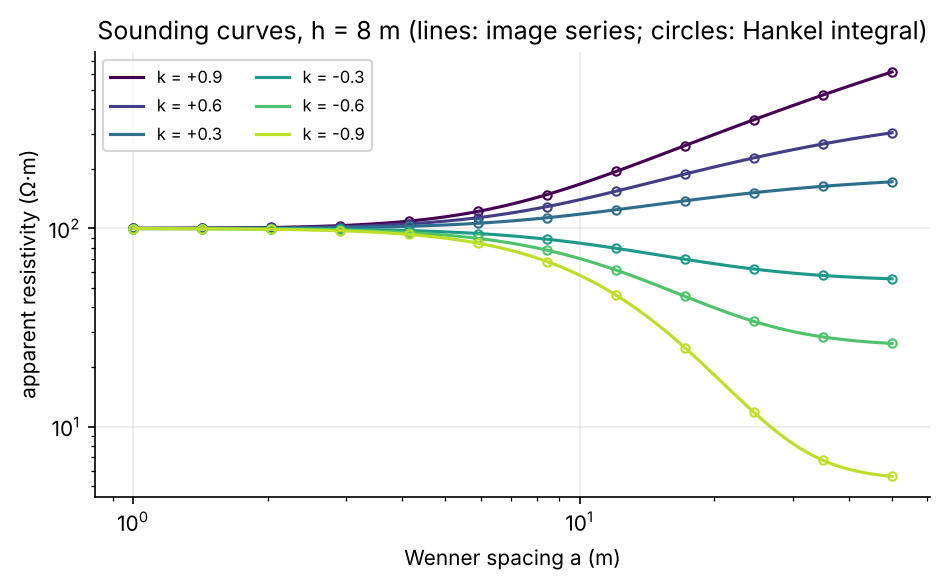

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 4))
a_f = np.logspace(0, np.log10(50), 120)
for k, c in zip([.9,.6,.3,-.3,-.6,-.9], plt.cm.viridis(np.linspace(0,.9,6))):
    ax.loglog(a_f, rho_a(a_f,RHO1,k,H_TRUE), color=c, label=f"k = {k:+.1f}")
    ax.loglog(A_SP, rho_a_hankel(A_SP,RHO1,k,H_TRUE), "o", color=c, ms=4, mfc="none")
ax.set(xlabel="Wenner spacing a (m)", ylabel="apparent resistivity (Ω·m)",
       title="Sounding curves, h = 8 m (lines: image series; circles: Hankel integral)")
ax.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

## 2. The variational circuit and the decoding map

Three qubits, three layers. Each layer applies $R_Y(\theta)R_Z(\phi)$ on every qubit and then a ring of CX gates, giving $3\times3\times2=18$ trainable angles. We read the Pauli-$Z$ expectation values of qubits 0 and 1, each in $[-1,1]$, and map them linearly onto bounded physical ranges so every proposal is physical:

$$\hat k = 0.95\,\langle Z_0\rangle\in[-0.95,\,0.95],\qquad \hat h = 1+29\,\frac{1+\langle Z_1\rangle}{2}\ \text{m}\in[1,\,30]\ \text{m}.$$

The cost is the mean squared difference of $\log_{10}\rho_a$ (logs because resistivity spans orders of magnitude):

$$\mathcal{L}(\boldsymbol\theta)=\frac1M\sum_{i=1}^{M}\Big[\log_{10}\rho_a^{\rm pred}(a_i;\hat k,\hat h)-\log_{10}\rho_a^{\rm obs}(a_i)\Big]^2 .$$

The circuit never sees the data; it only proposes $(\hat k,\hat h)$, and the physics turns each proposal into a predicted curve.

trainable angles: 18


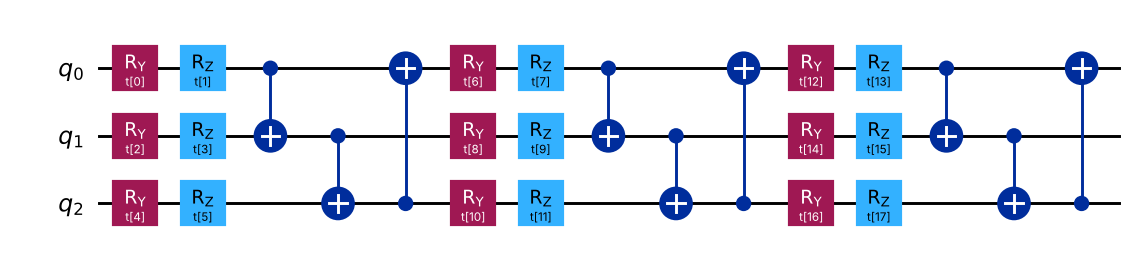

In [5]:
def make_circuit(n_qubits=3, n_layers=3):
    th = ParameterVector("t", 2*n_qubits*n_layers)
    qc = QuantumCircuit(n_qubits); i = 0
    for _ in range(n_layers):
        for q in range(n_qubits):
            qc.ry(th[i], q); qc.rz(th[i+1], q); i += 2
        for q in range(n_qubits):
            qc.cx(q, (q+1) % n_qubits)
    return qc

QC = make_circuit()
print("trainable angles:", QC.num_parameters)
try:
    display(QC.draw("mpl", fold=40, scale=.7))
except Exception:      # pylatexenc missing: fall back to a text diagram
    print(QC.draw("text", fold=110))

In [6]:
KMAX, HMIN, HMAX = 0.95, 1.0, 30.0
_circuits = {}

def zvals(x, n_qubits=3, n_layers=3, shots=None, rng_=None):
    # <Z_q> for every qubit; exact, or estimated from `shots` samples
    key = (n_qubits, n_layers)
    if key not in _circuits: _circuits[key] = make_circuit(*key)
    p = Statevector(_circuits[key].assign_parameters(x)).probabilities()
    if shots is not None:
        p = rng_.multinomial(shots, p/p.sum())/shots
    idx = np.arange(len(p))
    return np.array([float(((1-2*((idx>>q)&1))*p).sum()) for q in range(n_qubits)])

def decode(z, free_rho=False):
    k = KMAX*z[0]; h = HMIN + (HMAX-HMIN)*(1+z[1])/2
    rho1 = 10**(1 + 2*(1+z[2])/2) if free_rho else RHO1     # 10..1000 ohm-m if free
    return float(k), float(h), float(rho1)

def misfit(pred, obs): return float(np.mean((np.log10(pred)-np.log10(obs))**2))

def make_cost(obs, n_qubits=3, n_layers=3, free_rho=False):
    def cost(x):
        k, h, r1 = decode(zvals(x, n_qubits, n_layers), free_rho)
        return misfit(rho_a(A_SP, r1, k, h), obs)
    return cost

DATA = rho_a(A_SP, RHO1, K_TRUE, H_TRUE)        # noise-free synthetic observations
cost = make_cost(DATA)
print("example misfit at a random starting point:", round(cost(rng.normal(0, .3, 18)), 5))

example misfit at a random starting point: 0.02432


## 3. Inversion: hybrid COBYLA versus classical least squares

Data are generated by the validated forward model. For the main run we use five random COBYLA starts and compare with bounded least squares on $(k,h)$ directly, with no circuit involved.

In [7]:
def run_cobyla(cost, n_params, seed, maxiter=600, scale=0.3, center=0.0):
    r = np.random.default_rng(seed); trace = []
    def f(x): v = cost(x); trace.append(v); return v
    res = minimize(f, r.normal(center, scale, n_params), method="COBYLA", options={"maxiter": maxiter})
    return res, np.minimum.accumulate(trace)

def first_below(best_so_far, thr=1e-10):
    return int(np.argmax(best_so_far < thr)) + 1 if (best_so_far < thr).any() else None

t0 = time.time(); runs = []
for s in range(5):
    res, tr = run_cobyla(cost, 18, seed=SEED+s)
    k, h, _ = decode(zvals(res.x)); runs.append((res, tr, k, h))
    print(f"start {s+1}: misfit {res.fun:.1e}  k={k:.4f}  h={h:.3f} m  evals to 1e-10: {first_below(tr)}")
best = min(runs, key=lambda r: r[0].fun); k_q, h_q = best[2], best[3]

ls = least_squares(lambda p: np.log10(rho_a(A_SP, RHO1, *p)) - np.log10(DATA),
                   x0=[0.0, 10.0], bounds=([-.95, 1], [.95, 30]))
print(f"\ntrue      k={K_TRUE:.4f}  h={H_TRUE:.3f} m")
print(f"hybrid    k={k_q:.4f}  h={h_q:.3f} m   ({sum(r[0].nfev for r in runs)} evaluations over 5 starts)")
print(f"least-sq  k={ls.x[0]:.4f}  h={ls.x[1]:.3f} m   ({ls.nfev} evaluations)   [{time.time()-t0:.0f} s]")

start 1: misfit 4.8e-12  k=0.6000  h=8.000 m  evals to 1e-10: 192


start 2: misfit 4.5e-11  k=0.6000  h=8.001 m  evals to 1e-10: 251


start 3: misfit 1.5e-10  k=0.6001  h=8.001 m  evals to 1e-10: None


start 4: misfit 3.4e-12  k=0.6000  h=8.000 m  evals to 1e-10: 151


start 5: misfit 7.7e-13  k=0.6000  h=8.000 m  evals to 1e-10: 103

true      k=0.6000  h=8.000 m
hybrid    k=0.6000  h=8.000 m   (994 evaluations over 5 starts)
least-sq  k=0.6000  h=8.000 m   (7 evaluations)   [5 s]


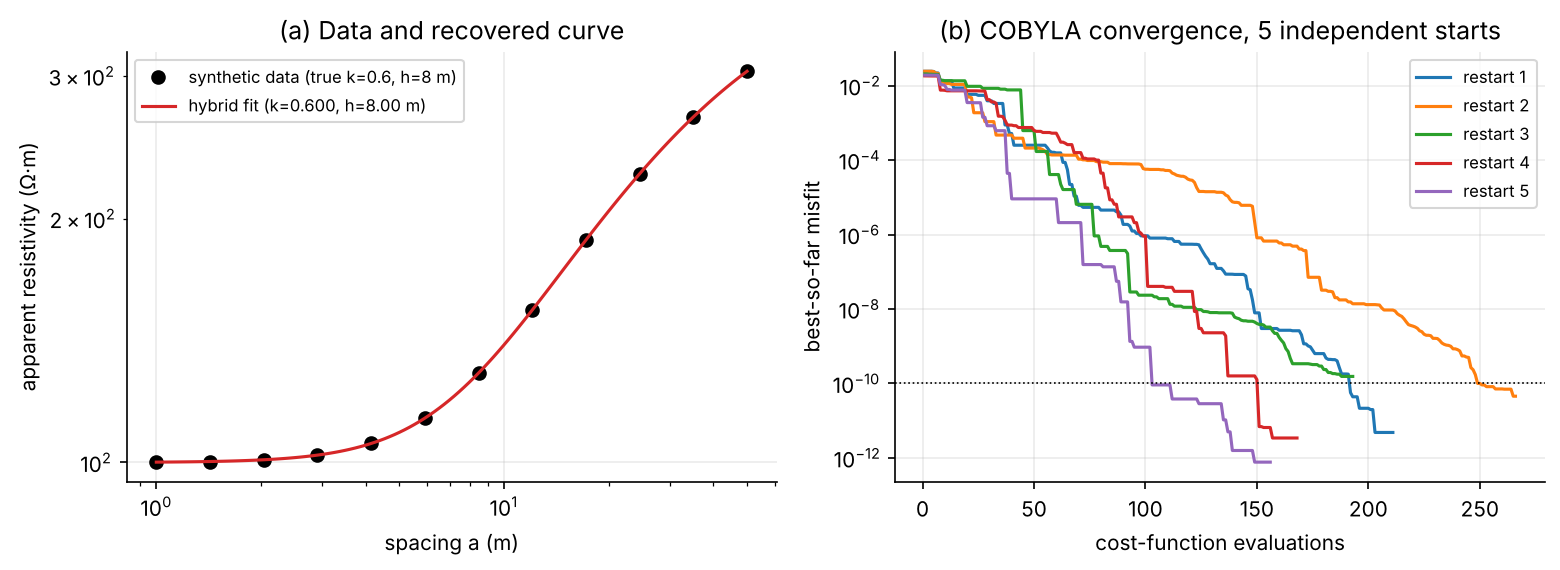

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9))
a_f = np.logspace(0, np.log10(50), 120)
ax[0].loglog(A_SP, DATA, "ko", label="synthetic data (true k=0.6, h=8 m)")
ax[0].loglog(a_f, rho_a(a_f, RHO1, k_q, h_q), "-", color="tab:red", label=f"hybrid fit (k={k_q:.3f}, h={h_q:.2f} m)")
ax[0].set(xlabel="spacing a (m)", ylabel="apparent resistivity (Ω·m)", title="(a) Data and recovered curve"); ax[0].legend(fontsize=8)
for i, (res, tr, *_ ) in enumerate(runs):
    ax[1].semilogy(np.arange(1, len(tr)+1), np.maximum(tr, 1e-16), label=f"restart {i+1}")
ax[1].axhline(1e-10, color="k", ls=":", lw=.8)
ax[1].set(xlabel="cost-function evaluations", ylabel="best-so-far misfit", title="(b) COBYLA convergence, 5 independent starts"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.1 Noise-free statistics over six contrasts (10 restarts each)

In [9]:
CONTRASTS = [0.9, 0.6, 0.3, -0.3, -0.6, -0.9]
NR = 3 if QUICK else 10
table = {}
t0 = time.time()
for kt in CONTRASTS:
    obs = rho_a(A_SP, RHO1, kt, H_TRUE); cst = make_cost(obs)
    ok, hits, fin = 0, [], []
    for r_ in range(NR):
        res, tr = run_cobyla(cst, 18, seed=1000+r_)
        k, h, _ = decode(zvals(res.x)); ok += (abs(k-kt) < .01 and abs(h-H_TRUE) < .1)
        fin.append(res.fun); hits.append(first_below(tr))
    l = least_squares(lambda p: np.log10(rho_a(A_SP, RHO1, *p)) - np.log10(obs), x0=[0., 10.], bounds=([-.95,1],[.95,30]))
    h_ = [x for x in hits if x]
    table[kt] = dict(conv=ok, med_evals=float(np.median(h_)) if h_ else None, med_misfit=float(np.median(fin)),
                     ls_ok=bool(abs(l.x[0]-kt)<.01 and abs(l.x[1]-H_TRUE)<.1), ls_nfev=int(l.nfev))
print(f"{'true k':>7} {'hybrid conv.':>13} {'median evals→1e-10':>19} {'median final misfit':>20} {'LS ok':>6} {'LS evals':>9}")
for kt, d in table.items():
    print(f"{kt:+7.1f} {d['conv']:>9d}/{NR:<3d} {str(d['med_evals']):>19} {d['med_misfit']:20.1e} {str(d['ls_ok']):>6} {d['ls_nfev']:9d}")
print(f"[{time.time()-t0:.0f} s]")

 true k  hybrid conv.  median evals→1e-10  median final misfit  LS ok  LS evals
   +0.9        10/10                302.0              9.7e-11   True        10
   +0.6        10/10                224.0              4.6e-11   True         7
   +0.3        10/10                282.0              6.8e-10   True         6
   -0.3        10/10                161.0              3.4e-10   True         6
   -0.6        10/10                164.0              1.3e-10   True         6
   -0.9        10/10                161.0              1.7e-11   True         9
[103 s]


## 4. The equivalence valley

Different $(k,h)$ pairs can produce almost the same sounding curve: a thicker layer with a larger contrast mimics a thinner layer with a smaller one. This is the geophysical non-uniqueness known as *equivalence*, and it is a property of the data, not of the optimiser. The figure maps the misfit over the full decode box with the true model marked.

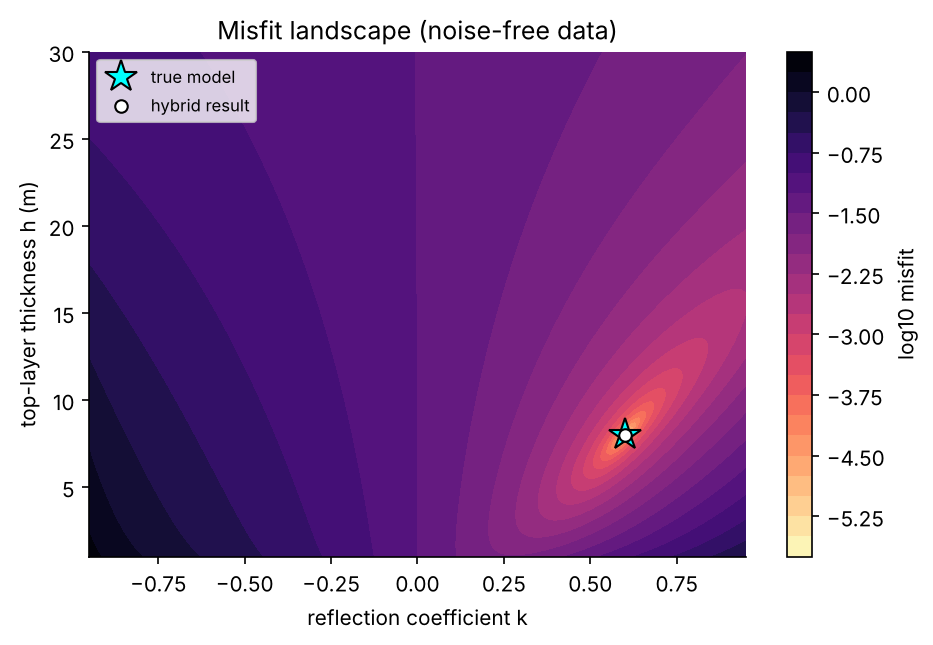

In [10]:
kk = np.linspace(-.95, .95, 161); hh = np.linspace(1, 30, 161)
L = np.array([[misfit(rho_a(A_SP, RHO1, k, h), DATA) for k in kk] for h in hh])
fig, ax = plt.subplots(figsize=(6.4, 4.4))
cs = ax.contourf(kk, hh, np.log10(L+1e-14), levels=24, cmap="magma_r")
plt.colorbar(cs, label="log10 misfit")
ax.plot(K_TRUE, H_TRUE, "*", color="cyan", ms=16, mec="k", label="true model")
ax.plot(k_q, h_q, "o", color="white", mec="k", ms=6, label="hybrid result")
ax.set(xlabel="reflection coefficient k", ylabel="top-layer thickness h (m)", title="Misfit landscape (noise-free data)"); ax.legend(loc="upper left", fontsize=8)
ax.grid(False); plt.tight_layout(); plt.show()

## 5. Noise robustness

Gaussian multiplicative noise (1 %, 3 %, 5 %) on the observed $\rho_a$. For every dataset we keep the best of several hybrid restarts and the best of several least-squares starts.

 noise |       hybrid k   hybrid h (m) |           LS k       LS h (m)   (true 0.6, 8 m)
    1% |  0.597±0.004    7.98±0.09  |  0.597±0.004    7.98±0.09
    3% |  0.600±0.011    7.99±0.21  |  0.600±0.011    7.99±0.21
    5% |  0.588±0.026    7.78±0.56  |  0.588±0.026    7.78±0.56
[125 s]


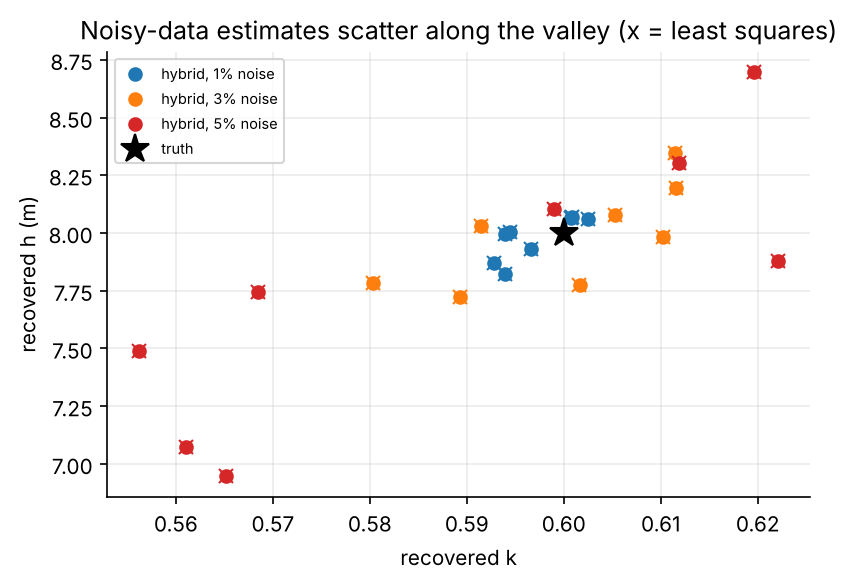

In [11]:
NREAL, NHYB, NLS = (3, 2, 3) if QUICK else (8, 4, 6)
noise_rows = {}
t0 = time.time()
for sig in [0.01, 0.03, 0.05]:
    qk, qh, lk, lh = [], [], [], []
    for r_ in range(NREAL):
        rg = np.random.default_rng(5000 + int(sig*1000)*100 + r_)
        obs = DATA*(1 + sig*rg.normal(size=DATA.size)); cst = make_cost(obs)
        bq = min((run_cobyla(cst, 18, seed=7000+100*r_+j)[0] for j in range(NHYB)), key=lambda r: r.fun)
        k, h, _ = decode(zvals(bq.x)); qk.append(k); qh.append(h)
        bl = min((least_squares(lambda p: np.log10(rho_a(A_SP,RHO1,*p))-np.log10(obs),
                  x0=[rg.uniform(-.9,.9), rg.uniform(2,28)], bounds=([-.95,1],[.95,30])) for _ in range(NLS)), key=lambda r: r.cost)
        lk.append(bl.x[0]); lh.append(bl.x[1])
    noise_rows[sig] = (np.array(qk), np.array(qh), np.array(lk), np.array(lh))
print(f"{'noise':>6} | {'hybrid k':>14} {'hybrid h (m)':>14} | {'LS k':>14} {'LS h (m)':>14}   (true 0.6, 8 m)")
for s, (qk, qh, lk, lh) in noise_rows.items():
    print(f"{s*100:5.0f}% | {qk.mean():6.3f}±{qk.std():.3f}  {qh.mean():6.2f}±{qh.std():.2f}  | {lk.mean():6.3f}±{lk.std():.3f}  {lh.mean():6.2f}±{lh.std():.2f}")
print(f"[{time.time()-t0:.0f} s]")

fig, ax = plt.subplots(figsize=(5.6, 4))
for (s, (qk, qh, lk, lh)), c in zip(noise_rows.items(), ["tab:blue","tab:orange","tab:red"]):
    ax.plot(qk, qh, "o", color=c, label=f"hybrid, {s*100:.0f}% noise"); ax.plot(lk, lh, "x", color=c, ms=7)
ax.plot(K_TRUE, H_TRUE, "*", color="k", ms=14, label="truth"); ax.set(xlabel="recovered k", ylabel="recovered h (m)", title="Noisy-data estimates scatter along the valley (x = least squares)")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 6. Finite-shot SPSA

On hardware, expectation values are estimated from a finite number of shots. We emulate this by multinomial sampling of the exact outcome probabilities (this is **not** a hardware or Aer noise model). SPSA estimates the gradient from two cost evaluations per step:

$$\hat g_k=\frac{\mathcal L(\boldsymbol\theta+c_k\boldsymbol\Delta)-\mathcal L(\boldsymbol\theta-c_k\boldsymbol\Delta)}{2c_k}\,\boldsymbol\Delta^{-1},\qquad \boldsymbol\Delta\in\{\pm1\}^{18},\quad a_k=\frac{a_0}{(k+1+A)^{0.602}},\ c_k=\frac{c_0}{(k+1)^{0.101}} .$$

Initial angles are drawn around $\pi/2$; see Section 7.1 for why this matters. The gain $a_0$ was chosen by a small sweep ($a_0\in\{0.5,1,2,5,10,20,40\}$, $c_0\in\{0.1,0.2,0.3\}$, 5 seeds); small gains barely move the angles in 600 iterations. Note these SPSA numbers differ slightly from the submitted report, which came from an earlier run with its own settings.

In [12]:
def spsa(seed, iters=600, shots=2000, a0=20.0, c0=0.2, A=40, center=np.pi/2, scale=0.5):
    r = np.random.default_rng(seed); x = r.normal(center, scale, 18)
    def noisy_cost(x_):
        k, h, _ = decode(zvals(x_, shots=shots, rng_=r)); return misfit(rho_a(A_SP, RHO1, k, h), DATA)
    for i in range(iters):
        ak = a0/(i+1+A)**0.602; ck = c0/(i+1)**0.101
        d = r.choice([-1., 1.], 18)
        g = (noisy_cost(x+ck*d) - noisy_cost(x-ck*d))/(2*ck)*d
        x = x - ak*g
    return x

NS = 3 if QUICK else 10
sp = []
t0 = time.time()
for s in range(NS):
    k, h, _ = decode(zvals(spsa(300+s))); sp.append((k, h))
sp = np.array(sp)
print(f"SPSA, 2000 shots, {NS} seeds (evaluated at final angles, exact expectations)")
print(f"k = {sp[:,0].mean():.3f} ± {sp[:,0].std():.3f}   (true 0.6)\nh = {sp[:,1].mean():.2f} ± {sp[:,1].std():.2f} m  (true 8)   [{time.time()-t0:.0f} s]")

SPSA, 2000 shots, 10 seeds (evaluated at final angles, exact expectations)
k = 0.662 ± 0.014   (true 0.6)
h = 8.71 ± 0.32 m  (true 8)   [28 s]


## 7. Diagnostics added after the judges' feedback

The judges asked two questions we did not answer rigorously in the report: *how did you detect barren plateaus?* and *why 18 parameters for 2 unknowns?* This section answers them with data, and also tests the three-parameter extension (free $\rho_1$) that the report only proposed.

### 7.1 Initialisation and gradients: a stationary point, not (yet) a barren plateau

At $\boldsymbol\theta=\mathbf 0$ the circuit leaves $|000\rangle$ unchanged, so $\langle Z\rangle=(1,1,1)$, which decodes to $(\hat k,\hat h)=(0.95,\,30\ \text{m})$. Every $\langle Z\rangle$ is at a maximum of $\cos\theta$ there, so the gradient is **exactly zero**. This is why SPSA initialised near zero stalled. It is a stationary point created by our decoding bounds and initialisation. A true *barren plateau* (McClean et al., 2018) is different: gradient *variance* shrinking exponentially with qubit count. We therefore test both.

In [13]:
cost = make_cost(DATA)
def grad_fd(f, x, e=1e-5):
    return np.array([(f(x+e*u)-f(x-e*u))/(2*e) for u in np.eye(len(x))])

NG = 30 if QUICK else 150
r = np.random.default_rng(5)
inits = {"θ≈0, N(0,0.05²)": lambda: r.normal(0, .05, 18),
         "COBYLA start, N(0,0.3²)": lambda: r.normal(0, .3, 18),
         "SPSA start, N(π/2,0.5²)": lambda: r.normal(np.pi/2, .5, 18),
         "uniform [0,2π]": lambda: r.uniform(0, 2*np.pi, 18)}
g_stats = {}
for name, g in inits.items():
    G = np.array([grad_fd(cost, g()) for _ in range(NG)])
    g_stats[name] = (np.median(np.linalg.norm(G, axis=1)), G.var(axis=0).mean())
z0 = zvals(np.zeros(18)); print("⟨Z⟩ at θ = 0:", z0, "-> (k,h) =", decode(z0)[:2], " |grad| =", np.linalg.norm(grad_fd(cost, np.zeros(18))))
print(f"\n{'initialisation':28s}{'median |∇L|':>14s}{'mean var(∂L/∂θ)':>18s}")
for n_, (m, v) in g_stats.items(): print(f"{n_:28s}{m:14.4f}{v:18.2e}")

⟨Z⟩ at θ = 0: [1. 1. 1.] -> (k,h) = (0.95, 30.0)  |grad| = 0.0

initialisation                 median |∇L|   mean var(∂L/∂θ)
θ≈0, N(0,0.05²)                     0.0030          7.27e-07
COBYLA start, N(0,0.3²)             0.0172          2.60e-05
SPSA start, N(π/2,0.5²)             0.0885          9.62e-04
uniform [0,2π]                      0.0945          1.72e-03


**Scaling test (barren-plateau signature).** Variance of $\partial\langle Z_0\rangle/\partial\theta_1$ over random initialisations, exact parameter-shift rule, as the number of qubits grows (3 layers each). An exponential decay with $n$ is the signature.

2 qubits: Var = 0.1262
3 qubits: Var = 0.0462
4 qubits: Var = 0.0257
5 qubits: Var = 0.0141
6 qubits: Var = 0.0066
7 qubits: Var = 0.0041
8 qubits: Var = 0.0020


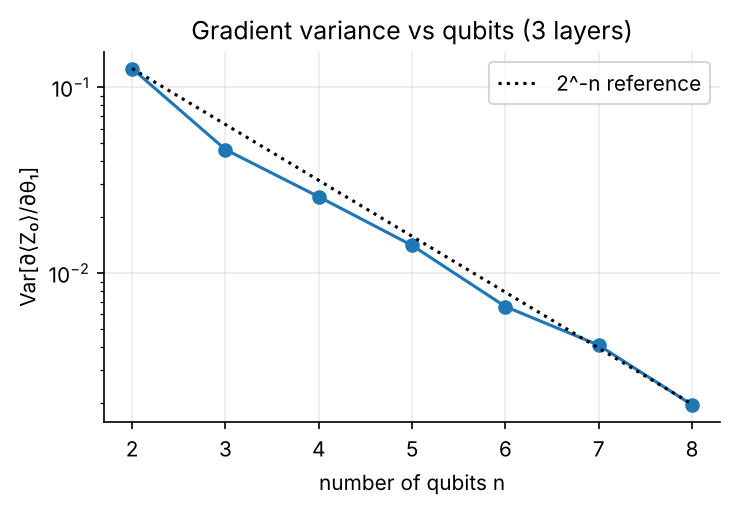

In [14]:
def var_dz0(n, samples):
    r_ = np.random.default_rng(n); v = []
    for _ in range(samples):
        x = r_.uniform(0, 2*np.pi, 2*n*3); xp, xm = x.copy(), x.copy(); xp[0] += np.pi/2; xm[0] -= np.pi/2
        v.append((zvals(xp, n, 3)[0] - zvals(xm, n, 3)[0])/2)
    return np.var(v)
ns = list(range(2, 7 if QUICK else 9)); vs = [var_dz0(n, 60 if QUICK else 120) for n in ns]
for n, v in zip(ns, vs): print(f"{n} qubits: Var = {v:.4f}")
fig, ax = plt.subplots(figsize=(5, 3.5)); ax.semilogy(ns, vs, "o-"); ax.semilogy(ns, vs[0]*2.0**-(np.array(ns)-ns[0]), "k:", label="2^-n reference")
ax.set(xlabel="number of qubits n", ylabel="Var[∂⟨Z₀⟩/∂θ₁]", title="Gradient variance vs qubits (3 layers)"); ax.legend(); plt.tight_layout(); plt.show()

**Reading.** At 3 qubits the variance is about 0.05, which is healthy, so our circuit is not in a barren plateau. The roughly 2× drop per added qubit shows the problem would appear if the circuit were scaled up. Initialising near $\theta=0$ cuts the gradient about 30× compared with a $\pi/2$ start, because it starts at a stationary point, which is what stalled SPSA.

### 7.2 Why 18 parameters? Circuit-size ablation

Same problem, same COBYLA budget, 1 to 4 layers (6 to 24 angles).

In [15]:
NABL = 4 if QUICK else 10
abl = {}
t0 = time.time()
for Ly in [1, 2, 3, 4]:
    cst = make_cost(DATA, 3, Ly); ok, hits = 0, []
    for r_ in range(NABL):
        res, tr = run_cobyla(cst, 6*Ly, seed=42+r_, maxiter=800)
        k, h, _ = decode(zvals(res.x, 3, Ly)); ok += (abs(k-K_TRUE) < .01 and abs(h-H_TRUE) < .1)
        if first_below(tr): hits.append(first_below(tr))
    abl[Ly] = (6*Ly, ok, float(np.median(hits)) if hits else None)
print(f"{'layers':>6} {'angles':>7} {'converged':>11} {'median evals → 1e-10':>22}")
for Ly, (p, ok, m) in abl.items(): print(f"{Ly:6d} {p:7d} {ok:>7d}/{NABL:<3d} {str(m):>22}")
print(f"[{time.time()-t0:.0f} s]")

layers  angles   converged   median evals → 1e-10
     1       6      10/10                   131.0
     2      12      10/10                   191.0
     3      18      10/10                   171.5
     4      24      10/10                   230.5
[48 s]


**Reading.** Even 6 angles suffice for this toy problem. The 18-angle circuit is a standard hardware-efficient choice, not a necessity: the extra angles bring no accuracy benefit here and the evaluation count does not fall with depth. Exact counts vary from run to run, and the circuit is in any case an expensive way to produce two numbers.

### 7.3 Three-parameter inversion (free $\rho_1$)

The third qubit's $\langle Z_2\rangle$ is mapped to a log-range $\rho_1\in[10,1000]\ \Omega\cdot$m: $\hat\rho_1=10^{\,1+2(1+\langle Z_2\rangle)/2}$.

In [16]:
cost3 = make_cost(DATA, 3, 3, free_rho=True)
N3 = 4 if QUICK else 10
rows3, t0 = [], time.time()
for r_ in range(N3):
    res, tr = run_cobyla(cost3, 18, seed=42+r_, maxiter=1500)
    k, h, r1 = decode(zvals(res.x), True)
    rows3.append((k, h, r1, res.fun, abs(k-K_TRUE) < .01 and abs(h-H_TRUE) < .1 and abs(r1-RHO1) < 2))
l3 = least_squares(lambda p: np.log10(rho_a(A_SP, *p[[0,1,2]]))-np.log10(DATA), x0=[50, 0., 10.], bounds=([10,-.95,1],[1000,.95,30]))
for i, (k, h, r1, f, ok) in enumerate(rows3): print(f"run {i+1:2d}: ρ1={r1:7.2f}  k={k:6.4f}  h={h:6.3f}  misfit={f:.1e}  {'ok' if ok else ''}")
print(f"\nhybrid within tolerance (|Δρ1|<2, |Δk|<0.01, |Δh|<0.1): {sum(r[4] for r in rows3)}/{N3} (1500-evaluation cap)")
print(f"least squares: ρ1={l3.x[0]:.3f}  k={l3.x[1]:.4f}  h={l3.x[2]:.3f}  in {l3.nfev} evaluations   [{time.time()-t0:.0f} s]")

run  1: ρ1=  99.97  k=0.5988  h= 7.968  misfit=8.5e-08  ok
run  2: ρ1= 100.36  k=0.6047  h= 8.195  misfit=2.6e-06  
run  3: ρ1= 100.52  k=0.6092  h= 8.347  misfit=8.3e-06  
run  4: ρ1= 100.01  k=0.6010  h= 8.024  misfit=5.8e-08  ok
run  5: ρ1= 100.04  k=0.6008  h= 8.027  misfit=5.2e-08  ok
run  6: ρ1= 100.28  k=0.6047  h= 8.168  misfit=2.0e-06  
run  7: ρ1= 100.01  k=0.6001  h= 8.005  misfit=1.6e-09  ok
run  8: ρ1= 100.02  k=0.6004  h= 8.012  misfit=1.2e-08  ok
run  9: ρ1= 100.15  k=0.6018  h= 8.085  misfit=5.3e-07  ok
run 10: ρ1=  99.89  k=0.5959  h= 7.888  misfit=1.1e-06  

hybrid within tolerance (|Δρ1|<2, |Δk|<0.01, |Δh|<0.1): 6/10 (1500-evaluation cap)
least squares: ρ1=100.000  k=0.6000  h=8.000  in 7 evaluations   [80 s]


**Reading.** With $\rho_1$ free, the hybrid loop recovers the truth within tolerance in only some restarts (6 of 10 in our run) and needs far more evaluations; the rest end on the equivalence valley. Least squares remains exact and instant. The path to field data therefore needs better optimisers or warm starts (see Section 8).

## 8. Summary and limitations

| Finding | Evidence |
|---|---|
| Forward model is correct | Five validation tests, including an independent Hankel-transform solver (Section 1.1) |
| The hybrid loop recovers $(k,h)$ from clean data | 10 restarts × 6 contrasts (Section 3.1) |
| Classical least squares is much cheaper | about 7 evaluations vs hundreds (Section 3) |
| Noisy data give valley-limited estimates, equal for both methods | Section 5 |
| Finite shots set an error floor for SPSA | Section 6 |
| Barren plateaus: not at 3 qubits, but gradient variance halves per added qubit | Section 7.1 |
| 18 angles are not necessary | 6 angles suffice (Section 7.2) |
| Free $\rho_1$ is harder for the hybrid loop | Section 7.3 |

**Limitations.** Two unknowns (three in Section 7.3), one array, synthetic data, exact-statevector simulation, finite shots emulated by sampling, no hardware and no Aer noise model. **No quantum advantage is claimed.**

**Next steps.** Warm-start the circuit with a classical solution; three-layer models; published field soundings; gradient-based training with the parameter-shift rule; hardware-efficient noise models.

## References

1. Telford, W.M., Geldart, L.P. and Sheriff, R.E. (1990). *Applied Geophysics*, 2nd ed. Cambridge University Press.
2. Koefoed, O. (1979). *Geosounding Principles 1: Resistivity Sounding Measurements*. Elsevier.
3. Cerezo, M. et al. (2021). Variational quantum algorithms. *Nature Reviews Physics*, 3, 625–644.
4. McClean, J.R. et al. (2018). Barren plateaus in quantum neural network training landscapes. *Nature Communications*, 9, 4812.
5. Spall, J.C. (1992). Multivariate stochastic approximation using a simultaneous perturbation gradient approximation. *IEEE Trans. Automatic Control*, 37, 332–341.
6. Powell, M.J.D. (1994). A direct search optimization method that models the objective and constraint functions by linear interpolation. In *Advances in Optimization and Numerical Analysis*, Kluwer.
7. Virtanen, P. et al. (2020). SciPy 1.0. *Nature Methods*, 17, 261–272.
8. Qiskit contributors. Qiskit: an open-source framework for quantum computing. https://qiskit.org

**AI-assistance statement.** Claude (Anthropic) assisted with the derivation write-up, code drafting and diagnostics; the team supplied the problem, design choices and review, and the results above are reproduced by running this notebook.